# Figure 5A - example EPM calcium traces

The four deposited `trace.csv` signals are plotted directly. The deposited
signals are already standardized (approximately zero mean and unit SD); no
additional z-score transformation is applied here. Colored spans identify each
preferred or non-preferred EPM arm. This is a representative reconstruction;
the final accepted example selection was not preserved in the submitted code.

**Inputs:** `data/source_data/figure_05/fig_5a_examples.csv` and
`fig_5a_traces.csv`  
**Output:** `results/figures/Fig_5A.png`

In [1]:
from pathlib import Path
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "pyproject.toml").is_file()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from utilities import (
    contiguous_intervals,
    ensure_directory,
    project_path,
    save_figure,
)

OUTPUT_DIR = ensure_directory(project_path("results", "figures", root=REPO_ROOT))

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
source_dir = project_path("data", "source_data", "figure_05", root=REPO_ROOT)
examples = pd.read_csv(source_dir / "fig_5a_examples.csv")
traces = pd.read_csv(source_dir / "fig_5a_traces.csv")
expected = ["Open-P-ON", "Open-NP-ON", "Closed-P-ON", "Closed-NP-ON"]
if examples["display_label"].tolist() != expected:
    raise AssertionError(f"Unexpected example labels: {examples['display_label'].tolist()}")
required = {"time_s", "arm", *examples["neuron"]}
if missing := required.difference(traces.columns):
    raise ValueError(f"Missing trace columns: {sorted(missing)}")
examples

,mouse_id,neuron,display_label,source_column
0,W01,C011,Open-P-ON,openPreferedON
1,W01,C002,Open-NP-ON,openNonPreferedON
2,W01,C012,Closed-P-ON,closePreferedON
3,W01,C004,Closed-NP-ON,closeNonPreferedON


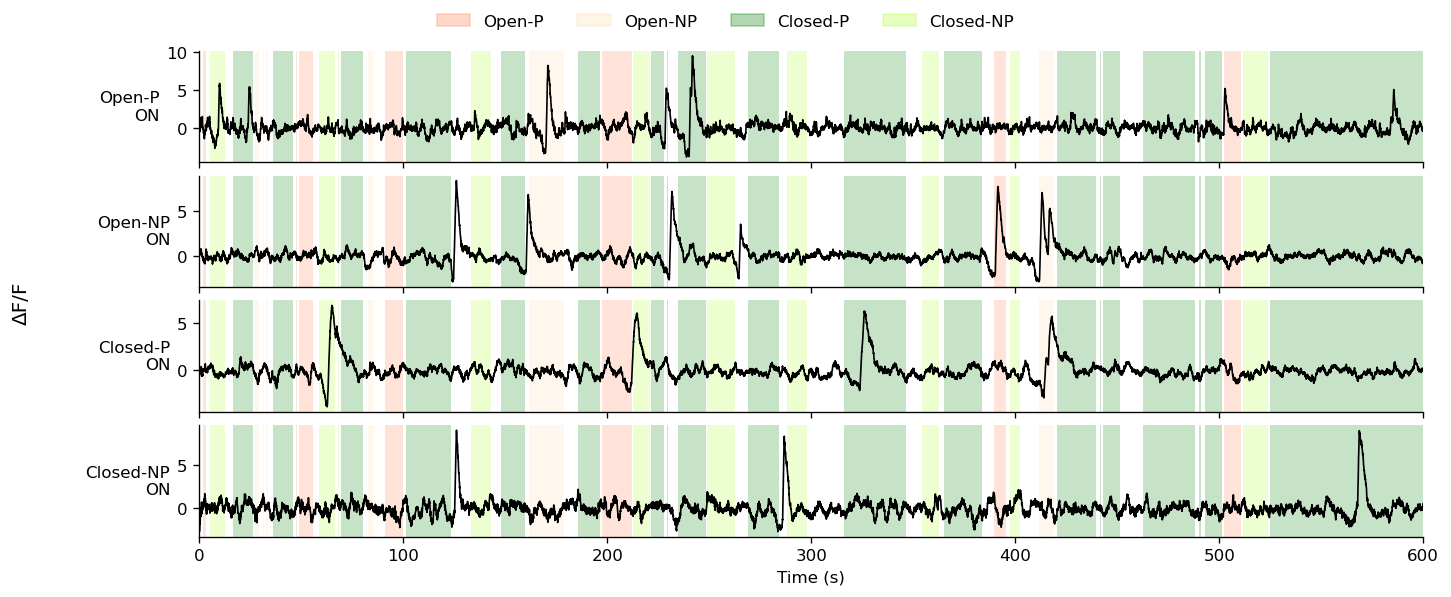

In [3]:
arm_colors = {
    "Open-P": "coral",
    "Open-NP": "navajowhite",
    "Closed-P": "green",
    "Closed-NP": "greenyellow",
}
time_s = traces["time_s"].to_numpy(dtype=float)
frame_dt = float(np.nanmedian(np.diff(time_s)))
arm_intervals = {
    arm: contiguous_intervals(traces["arm"].eq(arm).to_numpy())
    for arm in arm_colors
}

fig, axes = plt.subplots(4, 1, figsize=(12, 5), sharex=True)
fig.subplots_adjust(left=0.14, right=0.99, bottom=0.11, top=0.92, hspace=0.12)
for ax, row in zip(axes, examples.itertuples(index=False)):
    for arm, color in arm_colors.items():
        for start, stop in arm_intervals[arm]:
            ax.axvspan(time_s[start], time_s[stop] + frame_dt, color=color, alpha=0.22, linewidth=0)
    ax.plot(time_s, traces[row.neuron], color="black", linewidth=1)
    ax.set_ylabel(row.display_label.replace("-ON", "\nON"), rotation=0, ha="right", va="center")
    ax.margins(x=0)

axes[-1].set_xlabel("Time (s)")
fig.supylabel("ΔF/F", x=0.01)
fig.legend(
    handles=[mpl.patches.Patch(color=color, alpha=0.30, label=arm) for arm, color in arm_colors.items()],
    loc="upper center",
    ncol=4,
    frameon=False,
)

png_path = save_figure(fig, OUTPUT_DIR / "Fig_5A.png")
plt.show()
